# Can I fly?, advanced: how accurate the model is, the wind profile and flyable hours

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/drone_weather_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [Can I fly? Weather for drones](https://openskylab.space/edu_viz_drone_weather.html) · [česká verze](drone_weather_pro_cs.ipynb)

The advanced version of the drone weather notebook. You compare the Open-Meteo model with a week of real METAR reports from four Czech airports and compute how much the model errs in wind, temperature and dew point. Then, from three months of model data for Roztoky, you find out how the wind profile changes with atmospheric stability during the day and in which hours flying was possible most often.

**Goal:** decode a week of METAR reports, verify the model against them (bias, RMSE, correlation), compute the wind profile exponent and its dependence on temperature stratification, and build the daily cycle of the share of hours suitable for flying by wind, gusts, precipitation, visibility and icing.

**Data:** METAR reports for the last 7 days from Prague (LKPR), Brno (LKTB), Ostrava (LKMT) and Karlovy Vary (LKKV) airports from the NOAA Aviation Weather Center; hourly Open-Meteo data for the same 7 days at the airport coordinates and for 92 days for Roztoky (wind at 10, 80 and 120 m, gusts, temperature at 2 and 120 m, dew point, precipitation, visibility). Open-Meteo values for past days are stored short-range model forecasts, not measurements. The data change continuously, so your numbers will differ from the stored notebook.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 50 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup

In [1]:
import re, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

## 2. A week of METAR reports

We download the reports for 7 days, decode wind, gusts, temperature, dew point, visibility and cloud base and keep one report per hour. A report only carries the day of the month; month and year are taken from today's date.

In [2]:
AIRPORTS = {"LKPR": (50.1008, 14.2600), "LKTB": (49.1513, 16.6944), "LKMT": (49.6963, 18.1111), "LKKV": (50.2030, 12.9150)}  # ◀ parameter: airports and coordinates
raw = []
for code in AIRPORTS:                 # one airport at a time, the service returns at most about 400 reports per query
    raw += requests.get("https://aviationweather.gov/api/data/metar", params={"ids": code, "format": "raw", "hours": 168}, timeout=60).text.strip().splitlines()
now = pd.Timestamp.now(tz="UTC").tz_localize(None)
KT = 0.514444

def decode(m):
    body = re.split(r"\b(TEMPO|BECMG|NOSIG|RMK)\b", m)[0]
    dd, hh, mm = (int(x) for x in re.search(r"\b(\d{2})(\d{2})(\d{2})Z\b", body).groups())
    ts = now.replace(day=1, hour=hh, minute=mm, second=0, microsecond=0, nanosecond=0)
    ts = ts.replace(day=dd) if dd <= now.day else (ts - pd.DateOffset(months=1)).replace(day=dd)   # report from the previous month
    d = {"station": body.split()[1], "time": ts}
    w = re.search(r"\b(\d{3}|VRB)(\d{2,3})(?:G(\d{2,3}))?KT\b", body)
    if w:
        d["wind"] = int(w.group(2)) * KT; d["gusts"] = int(w.group(3)) * KT if w.group(3) else np.nan
    tt = re.search(r"\b(M?\d{2})/(M?\d{2})\b", body)
    if tt:
        d["T"], d["Td"] = (int(x.replace("M", "-")) for x in tt.groups())
    v = re.search(r"\s(\d{4})\s", body)
    d["visibility"] = 10000 if "CAVOK" in body else (int(v.group(1)) if v else np.nan)
    ceil = [int(h) * 30.48 for c, h in re.findall(r"\b(BKN|OVC|VV)(\d{3})", body)]
    d["ceiling"] = min(ceil) if ceil else np.nan
    d["precip"] = bool(re.search(r"(?<=\s)[-+]?(?:VC)?(?:SH|TS|FZ)?(?:DZ|RA|SN|SG|PL|GR|GS)", body + " "))
    return d

obs = pd.DataFrame([decode(m) for m in raw]).dropna(subset=["wind", "T"])
obs["hour"] = obs["time"].dt.round("h")
obs = obs.sort_values("time").groupby(["station", "hour"]).last().reset_index()   # one report per hour
print(f"{len(raw)} METAR reports, {len(obs)} hours with observations; from {obs['hour'].min()} to {obs['hour'].max()} UTC")
obs.groupby("station")[["wind", "gusts", "T", "Td"]].describe().loc[:, (slice(None), ["count", "mean", "max"])].round(1)

1268 METAR reports, 672 hours with observations; from 2026-10-24 10:00:00 to 2026-10-31 09:00:00 UTC


wind            gusts                  T                Td          
         count mean   max count  mean   max  count mean   max  count mean  max
station                                                                       
LKKV     168.0  2.2   6.7   5.0  10.3  10.8  168.0  5.2  14.0  168.0  3.0  9.0
LKMT     168.0  3.2   9.3   0.0   NaN   NaN  168.0  7.0  14.0  168.0  3.8  8.0
LKPR     168.0  3.8  11.8   1.0  16.5  16.5  168.0  7.0  13.0  168.0  3.8  9.0
LKTB     168.0  2.9   6.7   0.0   NaN   NaN  168.0  7.2  13.0  168.0  3.4  8.0

## 3. Verifying the model

For each airport we download hourly Open-Meteo data for the same 7 days and pair them with the reports. **Bias** is the mean of model − observation (systematic error), **RMSE** the root mean square of the difference (total error), **correlation** tells how well the model caught the course.

Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – retrying


Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – retrying


Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – retrying


Open-Meteo: SSLError – retrying


Open-Meteo: SSLError – retrying


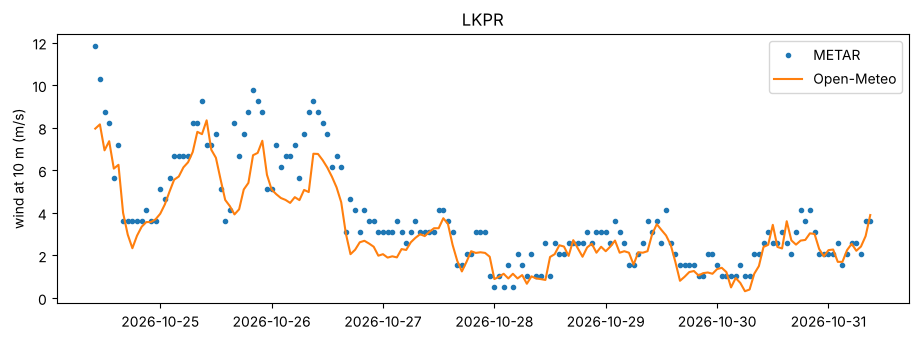

,hours,wind: model bias (m/s),wind: RMSE (m/s),wind: correlation,T: bias (°C),T: RMSE (°C),Td: bias (°C)
LKKV,168.0,-0.18,1.05,0.79,-0.08,0.94,-0.04
LKMT,168.0,-0.79,1.14,0.89,-0.04,0.92,0.38
LKPR,168.0,-0.67,1.17,0.93,-0.01,0.77,0.16
LKTB,168.0,-0.48,1.09,0.80,-0.34,0.93,-0.12


In [3]:
lats = ",".join(str(v[0]) for v in AIRPORTS.values()); lons = ",".join(str(v[1]) for v in AIRPORTS.values())
w = open_meteo({"latitude": lats, "longitude": lons, "past_days": 7, "forecast_days": 1, "wind_speed_unit": "ms", "timezone": "UTC",
                "hourly": "wind_speed_10m,wind_gusts_10m,temperature_2m,dew_point_2m"})
mod = pd.concat([pd.DataFrame(r["hourly"]).assign(station=k) for k, r in zip(AIRPORTS, w)])
mod["hour"] = pd.to_datetime(mod["time"])
cmp = obs.merge(mod, on=["station", "hour"])
rows = {}
for k, g in cmp.groupby("station"):
    rows[k] = {"hours": len(g),
               "wind: model bias (m/s)": (g.wind_speed_10m - g["wind"]).mean(), "wind: RMSE (m/s)": np.sqrt(((g.wind_speed_10m - g["wind"]) ** 2).mean()),
               "wind: correlation": g.wind_speed_10m.corr(g["wind"]),
               "T: bias (°C)": (g.temperature_2m - g["T"]).mean(), "T: RMSE (°C)": np.sqrt(((g.temperature_2m - g["T"]) ** 2).mean()),
               "Td: bias (°C)": (g.dew_point_2m - g["Td"]).mean()}
k0 = list(AIRPORTS)[0]
g = cmp[cmp.station == k0]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(g.hour, g["wind"], ".", label="METAR"); ax.plot(g.hour, g.wind_speed_10m, "-", label="Open-Meteo")
ax.set(ylabel="wind at 10 m (m/s)", title=k0); ax.legend(); plt.show()
pd.DataFrame(rows).T.round(2)

> **✏️ Task 1.** Does the model underestimate or overestimate the wind? How large is the RMSE compared with the typical wind speed at the airport? At which airport does the model fit worst, and what may cause it (surrounding terrain, a valley, model resolution)? Why does METAR give wind in whole knots, and what error does that alone introduce?

*Your answer:* 

> **✏️ Task 2.** How accurately does the model hit temperature and dew point? The cloud base estimate is 125 m per degree of T − Td: by how many metres does the estimate shift when the dew point is off by 1 °C? What follows for deciding about fog, low cloud and icing from the model?

*Your answer:* 

## 4. Wind profile and atmospheric stability

Wind grows with height approximately as u(z) = u(10 m) · (z / 10)^α. We compute the exponent α from the wind at 10 and 120 m for every hour over 92 days and compare it with the temperature difference between 120 and 2 m. If temperature falls with height faster than 1 °C per 100 m, the air is unstable and mixes; if it rises with height (an inversion), it is stable.

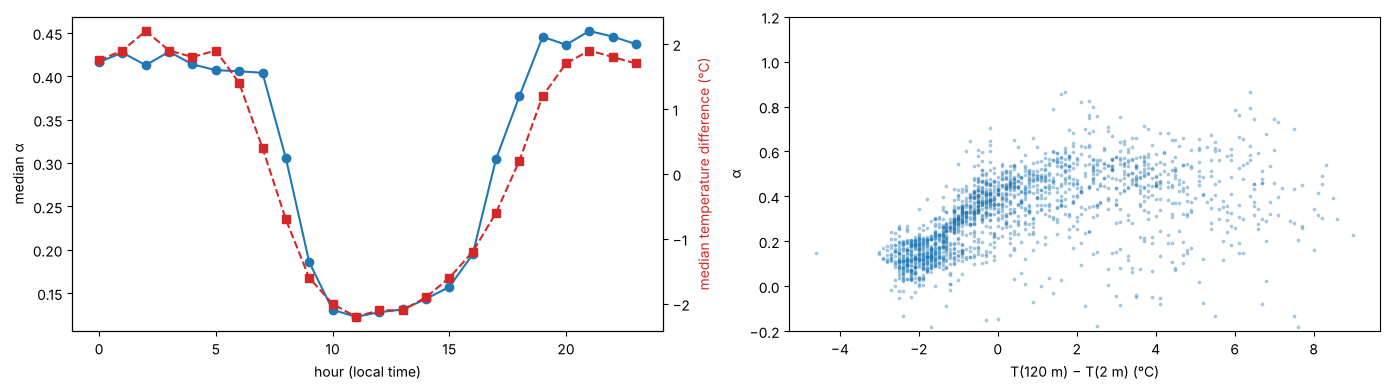

1799 hours; the dry adiabatic drop over 118 m is −1.15 °C


,hours,alpha,wind10,wind120
stability,,,,
unstable (< −1 °C),628,0.16,2.60,3.98
weakly unstable,354,0.36,2.51,6.30
weakly stable,217,0.42,2.31,6.33
inversion (> +1 °C),600,0.46,0.92,3.09


In [4]:
LAT, LON = 50.152, 14.392            # ◀ parameter: flight site (Roztoky)
w = open_meteo({"latitude": LAT, "longitude": LON, "past_days": 92, "forecast_days": 1, "wind_speed_unit": "ms", "timezone": "Europe/Prague",
                "hourly": "wind_speed_10m,wind_speed_80m,wind_speed_120m,wind_gusts_10m,temperature_2m,temperature_120m,dew_point_2m,precipitation,visibility"})
loc = pd.DataFrame(w["hourly"]); loc["time"] = pd.to_datetime(loc["time"]); loc = loc.set_index("time").dropna()
loc["alpha"] = np.log(loc.wind_speed_120m / loc.wind_speed_10m.clip(lower=0.5)) / np.log(120 / 10)   # exponent of the power-law profile
loc["dT"] = loc.temperature_120m - loc.temperature_2m                                               # temperature 120 m − 2 m
loc["stability"] = pd.cut(loc.dT, [-10, -1.0, 0.0, 1.0, 20], labels=["unstable (< −1 °C)", "weakly unstable", "weakly stable", "inversion (> +1 °C)"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
by_h = loc.groupby(loc.index.hour)
ax[0].plot(by_h.alpha.median(), "o-", label="exponent α"); ax2 = ax[0].twinx(); ax2.plot(by_h.dT.median(), "s--", color="C3", label="T(120 m) − T(2 m)")
ax[0].set(xlabel="hour (local time)", ylabel="median α"); ax2.set_ylabel("median temperature difference (°C)", color="C3")
ax[1].scatter(loc.dT, loc.alpha, s=3, alpha=0.3); ax[1].set(xlabel="T(120 m) − T(2 m) (°C)", ylabel="α", ylim=(-0.2, 1.2)); plt.tight_layout(); plt.show()
print(f"{len(loc)} hours; the dry adiabatic drop over 118 m is −1.15 °C")
loc.groupby("stability", observed=True).agg(hours=("alpha", "size"), alpha=("alpha", "median"), wind10=("wind_speed_10m", "median"), wind120=("wind_speed_120m", "median")).round(2)

> **✏️ Task 3.** Why is α large at night and in the morning and small during the day? Why is there almost no wind at the ground in an inversion while it blows at 120 m? What does it mean when you measure the wind with a hand anemometer before a morning take-off and estimate the wind at flight height from it? At what time does the inversion typically break up?

*Your answer:* 

## 5. Flyable hours over the last three months

For each hour over 92 days we evaluate the conditions like the traffic light in the basic version: wind at 120 m, estimated gusts at 120 m, precipitation, visibility and icing risk. The model does not give gusts at 120 m, so we estimate them from 10 m in two ways (`GUSTS`).

share of daytime hours (6–20 h) when the condition is met:
wind 120 m           96.0
gusts                65.5
no precipitation     90.7
visibility           95.4
no icing            100.0
fly                  58.0


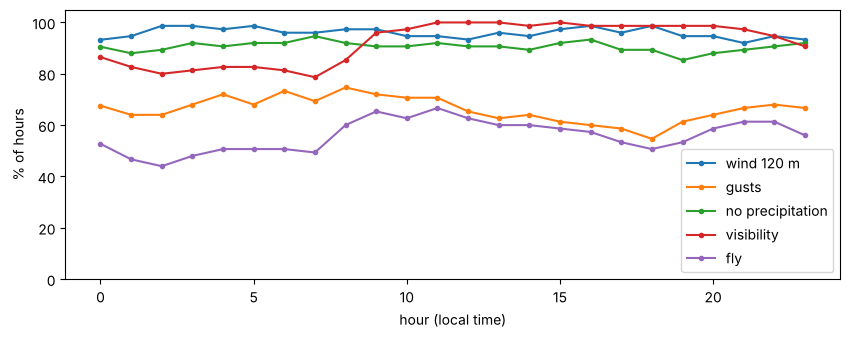

In [5]:
LIM_WIND, LIM_GUST = 10.0, 12.0      # ◀ parameter: limit for wind at 120 m and for gusts (m/s)
LIM_VIS = 5000                        # ◀ parameter: minimum visibility (m)
GUSTS = "ratio"                       # ◀ parameter: estimate of gusts at 120 m: "ratio" (the same gust/wind ratio as at 10 m) or "excess" (the same difference)
if GUSTS == "ratio":
    gust120 = loc.wind_gusts_10m * loc.wind_speed_120m / loc.wind_speed_10m.clip(lower=0.5)
else:
    gust120 = loc.wind_speed_120m + (loc.wind_gusts_10m - loc.wind_speed_10m)
ok = pd.DataFrame({"wind 120 m": loc.wind_speed_120m <= LIM_WIND, "gusts": gust120 <= LIM_GUST, "no precipitation": loc.precipitation < 0.1,
                   "visibility": loc.visibility >= LIM_VIS, "no icing": ~((loc.temperature_2m < 1) & (loc.temperature_2m - loc.dew_point_2m < 2))})
ok["fly"] = ok.all(axis=1)
day = ok[(ok.index.hour >= 6) & (ok.index.hour <= 20)]
print("share of daytime hours (6–20 h) when the condition is met:"); print((day.mean() * 100).round(1).to_string())
fig, ax = plt.subplots(figsize=(10, 3.5))
(ok.groupby(ok.index.hour).mean() * 100)[["wind 120 m", "gusts", "no precipitation", "visibility", "fly"]].plot(ax=ax, marker=".")
ax.set(xlabel="hour (local time)", ylabel="% of hours", ylim=(0, 105)); plt.show()

> **✏️ Task 4.** Which condition limited flying most often over the last three months, and at what time of day was the chance to fly best? Switch `GUSTS` to the other gust estimate: by how much does the share of flyable hours change? Which estimate do you think is closer to reality, and why (how do gusts change with height)?

*Your answer:* 

> **✏️ Task 5.** Set the limits for a smaller drone (`LIM_WIND = 8`, `LIM_GUST = 10.7` as the wind resistance of the DJI Mini 4 Pro) and then for stricter operation with imaging (visibility 8 km). How do the share of flyable hours and its daily cycle change? Why would this calculation turn out differently for the winter months?

*Your answer:* 

> **✏️ Extension (optional).** Add Linz airport (`"LOWL": (48.2332, 14.1875)`) or another to `AIRPORTS` and compare the model accuracy. Change `LAT, LON` to another flight site (for example Brno-Bystrc 49.2467, 16.4798) and compare the wind profile and flyable hours.

*Your answer:* 

---
### Data sources and references

- METAR: NOAA/NWS Aviation Weather Center, https://aviationweather.gov/data/api/ (US government public data).
- Weather: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- METAR code: ICAO Annex 3 / WMO-No. 306, code FM 15.
- Stull, R. B. (1988). *An Introduction to Boundary Layer Meteorology*. Kluwer (daily cycle of the boundary layer, stability, wind profile).
- Wind resistance of the DJI Mavic 3 Enterprise 12 m/s and of the DJI Mini 4 Pro 10.7 m/s (DJI data sheets).

### How to cite

OpenSkyLab (2026). Can I fly?, advanced: how accurate the model is, the wind profile and flyable hours [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/drone_weather_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*